# 03 – Analysis
Answers the business questions using `data/processed/access_clean.csv`.
Medians are used throughout because journey times are right-skewed.

## Q1. How does the access gap change from urban to remote rural areas?

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv(Path("../data/processed/access_clean.csv"))
print(df.shape)

(6976, 25)


In [3]:
q1 = (df.groupby(["UrbanRural6fold2020", "UR_class"])
        .agg(zones=("Data_Zone", "count"),
             drive_GP=("drive_GP", "median"),
             PT_GP=("PT_GP", "median"),
             gap_GP=("gap_GP", "median"),
             ratio_GP=("ratio_GP", "median"),
             gap_post=("gap_post", "median"),
             gap_retail=("gap_retail", "median"))
        .round(1)
        .reset_index())
q1

,UrbanRural6fold2020,UR_class,zones,drive_GP,PT_GP,gap_GP,ratio_GP,gap_post,gap_retail
0,1,Large Urban Areas,2496,2.5,7.5,4.9,3.0,4.7,6.0
1,2,Other Urban Areas,2459,3.0,9.5,6.3,3.2,5.3,7.1
2,3,Accessible Small Towns,613,2.5,8.0,5.2,3.2,4.6,6.0
3,4,Remote Small Towns,202,2.7,8.7,5.6,3.1,4.6,4.7
4,5,Accessible Rural,805,5.8,15.4,9.3,2.8,6.7,11.6
5,6,Remote Rural,401,6.9,18.4,11.0,2.7,8.0,13.0


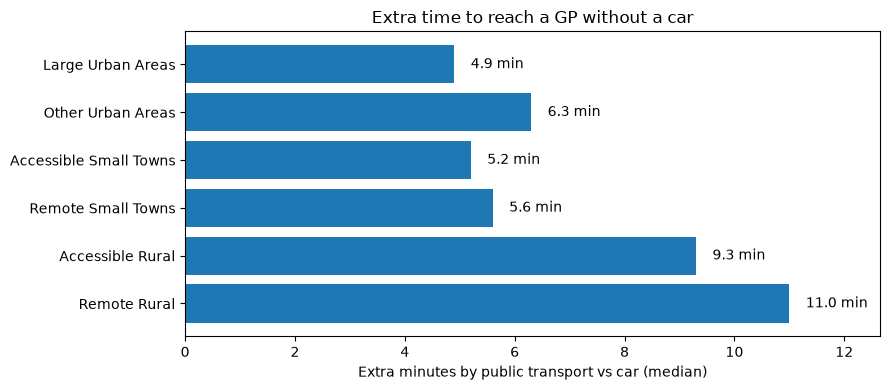

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(q1["UR_class"], q1["gap_GP"], color="#1f77b4")
ax.set_xlim(0, q1["gap_GP"].max() * 1.15)
ax.invert_yaxis()
ax.set_xlabel("Extra minutes by public transport vs car (median)")
ax.set_title("Extra time to reach a GP without a car")

for i, v in enumerate(q1["gap_GP"]):
    ax.text(v + 0.3, i, f"{v} min", va="center")

plt.tight_layout()
plt.savefig("../images/q1_gap_by_rurality.png", dpi=150)
plt.show()

**Finding:** the extra time without a car more than doubles from Large Urban Areas (4.9 min to a GP)
to Remote Rural areas (11.0 min), with a step change between small towns and rural areas rather than
a steady rise. The ratio moves the other way (3.0× urban vs 2.7× remote rural) because driving is also
slower in rural areas, so the rural disadvantage is mainly in absolute time: 18.4 min by public
transport vs 7.5 min in large urban areas. The same pattern holds for post offices and retail centres.

## Q2. Which councils have the largest share of people over 15 minutes from a GP by public transport?
15 minutes matches the benchmark used in the Scottish Government's Rural Scotland Key Facts.
Shares are weighted by population so councils are compared by people affected, not number of zones.

In [5]:
df["pop_over15"] = df["Total_population"].where(df["PT_GP"] > 15, 0)

q2 = (df.groupby("Council_area")
        .agg(population=("Total_population", "sum"),
             pop_over15=("pop_over15", "sum"),
             median_PT_GP=("PT_GP", "median"))
        .assign(pct_over15=lambda t: (100 * t["pop_over15"] / t["population"]).round(1))
        .sort_values("pct_over15", ascending=False))

print("Scotland:", round(100 * df["pop_over15"].sum() / df["Total_population"].sum(), 1), "% over 15 min")
q2.head(10)

Scotland: 16.0 % over 15 min


,population,pop_over15,median_PT_GP,pct_over15
Council_area,,,,
Na h-Eileanan an Iar,26950,15403,17.270860,57.2
Shetland Islands,23080,12495,18.655276,54.1
Aberdeenshire,261800,117902,13.450946,45.0
Orkney Islands,22000,9750,13.793337,44.3
Highland,235180,103362,13.505943,44.0
Angus,116280,45896,11.615638,39.5
Argyll and Bute,86810,29952,11.861208,34.5
Scottish Borders,115020,39533,10.329321,34.4
Moray,95780,30437,12.496288,31.8


**Finding:** 16.0% of Scotland's population live in data zones more than 15 minutes from a GP by
public transport. Rates are highest in the island councils (Na h-Eileanan Siar 57.2%, Shetland 54.1%,
Orkney 44.3%), followed by Aberdeenshire (45.0%) and Highland (44.0%). By number of people,
Aberdeenshire is the most affected council (~118,000 residents), ahead of Highland (~103,000).

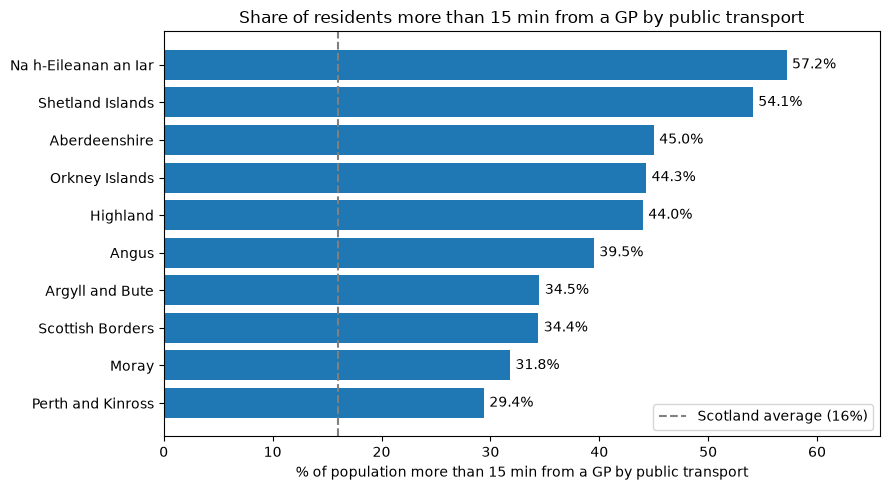

In [6]:
top10 = q2.head(10).sort_values("pct_over15")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top10.index, top10["pct_over15"], color="#1f77b4")
ax.axvline(16.0, color="grey", linestyle="--", label="Scotland average (16%)")
ax.legend(loc="lower right")
ax.set_xlim(0, top10["pct_over15"].max() * 1.15)
ax.set_xlabel("% of population more than 15 min from a GP by public transport")
ax.set_title("Share of residents more than 15 min from a GP by public transport")

for i, v in enumerate(top10["pct_over15"]):
    ax.text(v + 0.5, i, f"{v}%", va="center")

plt.tight_layout()
plt.savefig("../images/q2_councils_over15.png", dpi=150)
plt.show()

## Q3. Are deprived rural areas doubly disadvantaged?
Zones are split into income deprivation quintiles (Scotland-wide, 1 = most deprived 20%).
For each urban-rural group and quintile, compare the share of people more than 15 minutes
from a GP by public transport, and count residents facing both disadvantages.

In [7]:
d = df.dropna(subset=["Income_rate"]).copy()
d["income_quintile"] = pd.qcut(d["Income_rate"].rank(method="first", ascending=False),
                               5, labels=[1, 2, 3, 4, 5])

q3 = d.pivot_table(index="UR_group", columns="income_quintile",
                   values=["pop_over15", "Total_population"], aggfunc="sum", observed=True)
q3_pct = (100 * q3["pop_over15"] / q3["Total_population"]).round(1)
q3_pct = q3_pct.loc[["Urban", "Small Towns", "Rural"]]
q3_pct

income_quintile,1,2,3,4,5
UR_group,,,,,
Urban,3.8,4.4,7.0,10.3,15.0
Small Towns,6.4,4.0,3.5,13.4,18.9
Rural,11.7,25.6,46.3,65.2,69.3


In [8]:
both = d[(d["income_quintile"].isin([1, 2])) & (d["PT_GP"] > 15)]
print(f"Residents in the 40% most income-deprived zones AND >15 min from a GP: "
      f"{both['Total_population'].sum():,}")
both.groupby("Council_area")["Total_population"].sum().sort_values(ascending=False).head(5)

Residents in the 40% most income-deprived zones AND >15 min from a GP: 110,110


Council_area
North Lanarkshire    16230
Highland              9741
East Ayrshire         9704
Renfrewshire          7273
South Ayrshire        7047
Name: Total_population, dtype: int64

In [9]:
q3["Total_population"].loc[["Urban", "Small Towns", "Rural"]]

income_quintile,1,2,3,4,5
UR_group,,,,,
Urban,954081,819932,650860,652299,808518
Small Towns,73022,145350,156522,121028,118895
Rural,30658,92556,269235,345353,186491


**Finding:** the hypothesis is not supported at neighbourhood level. In rural areas, only 11.7% of
people in the most income-deprived zones are more than 15 minutes from a GP by public transport,
compared with 69.3% in the least deprived; the same pattern appears in urban areas. Deprived rural
zones tend to be village or town centres, while more remote rural zones are better off.
However, 110,110 people live in zones that are both among the 40% most income-deprived and more than
15 minutes from a GP. The largest numbers are in North Lanarkshire, East Ayrshire, Renfrewshire and
South Ayrshire, suggesting the double disadvantage is concentrated in post-industrial areas of the
Central Belt and Ayrshire rather than in remote rural Scotland.

*Limitation:* zone-level data cannot show the circumstances of deprived individuals living in
less deprived zones, who may be most affected by poor public transport.

In [10]:
q2.tail(5)

,population,pop_over15,median_PT_GP,pct_over15
Council_area,,,,
North Ayrshire,135790,10640,8.214474,7.8
City of Edinburgh,513210,15201,6.990120,3.0
Aberdeen City,228800,6166,7.291528,2.7
Glasgow City,621020,9534,6.719505,1.5
East Renfrewshire,94760,551,8.695630,0.6


The lowest shares are in East Renfrewshire (0.6%), Glasgow City (1.5%), Aberdeen City (2.7%) and
City of Edinburgh (3.0%). Even so, Edinburgh's 3.0% represents 15,201 people, almost the same number
as in Na h-Eileanan Siar (15,403).

In [11]:
tableau = df.merge(d[["Data_Zone", "income_quintile"]], on="Data_Zone", how="left")
tableau.to_csv("../data/processed/tableau_data.csv", index=False)
print(tableau.shape, "| missing quintile:", tableau["income_quintile"].isna().sum())

(6976, 27) | missing quintile: 3
